## SQuARE Threshold Sensitivity — wikidata

SQuARE's positive/negative labels rest on two thresholds, chosen without
further justification in the paper: answer-set Jaccard **> 0.8** for
positives and **< 0.2** for negatives. This notebook checks whether the
paper's conclusions depend on the exact cut.

- **Experiment A** — is the pairwise Jaccard distribution bimodal, so the
  labels are insensitive to small threshold shifts?
- **Experiment B** — does the RQ1 SparqlCE-vs-baseline gap survive if the
  *evaluation-side* relevance threshold tau is swept, without retraining?

Checkpoint: `wikidata_model_mrr_0.3238.pt`. Wikidata counterpart:
`threshold_sensitivity_wikidata.ipynb` (not yet run).

In [1]:
import gc
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from tqdm.auto import tqdm

# Locate repository root by walking upward until datasets/ exists.
PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "datasets").exists():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Could not locate repository root containing datasets/")
    PROJECT_ROOT = PROJECT_ROOT.parent

RQ1_DIR = PROJECT_ROOT / "notebooks" / "evaluation-RQ1"
for path in [PROJECT_ROOT, RQ1_DIR]:
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

TESTSET_PATH = PROJECT_ROOT / "datasets" / "wikidata_testset_RQ1.json"
RESULTS_PATH = PROJECT_ROOT / "datasets" / "result_sets_wikidata.json"
SPARQLCE_CKPT = PROJECT_ROOT / "sparqlce" / "models" / "wikidata_model_mrr_0.3238.pt"
OUT_DIR = PROJECT_ROOT / "results" / "threshold_sensitivity"
OUT_DIR.mkdir(parents=True, exist_ok=True)

TAUS = [0.6, 0.7, 0.8, 0.9]   # 0.8 is the paper's construction threshold
TOPK = 10
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Keep this list identical to the baselines used in the paper's RQ1 evaluation.
BASELINES = [
    {"name": "E5-base-v2", "model_id": "intfloat/e5-base-v2", "prefix": "query: ", "batch_size": 32},
    {"name": "Qwen3-Embedding", "model_id": "Qwen/Qwen3-Embedding-0.6B", "prefix": "", "batch_size": 8},
]

print(f"project root: {PROJECT_ROOT}")
print(f"device: {DEVICE}")
print(f"output dir: {OUT_DIR}")

for required_path in [TESTSET_PATH, RESULTS_PATH, SPARQLCE_CKPT]:
    status = "OK" if required_path.exists() else "MISSING"
    print(f"{required_path}: {status}")
    if status == "MISSING":
        raise FileNotFoundError(required_path)

project root: /workspace/SPARQL-Embeddings
device: cuda
output dir: /workspace/SPARQL-Embeddings/results/threshold_sensitivity
/workspace/SPARQL-Embeddings/datasets/wikidata_testset_RQ1.json: OK
/workspace/SPARQL-Embeddings/datasets/result_sets_wikidata.json: OK
/workspace/SPARQL-Embeddings/sparqlce/models/wikidata_model_mrr_0.3238.pt: OK


/workspace/.conda/envs/sparql/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Experiment A — pairwise Jaccard distribution

In [2]:
def canonicalize_row(row) -> str:
    """Stable, hashable representation of a JSON result row (string, list, dict, or scalar)."""
    return json.dumps(row, sort_keys=True, ensure_ascii=False, separators=(",", ":"))


with open(RESULTS_PATH, encoding="utf-8") as f:
    raw_result_sets = json.load(f)

result_sets = {
    q: frozenset(canonicalize_row(row) for row in rows)
    for q, rows in raw_result_sets.items() if rows
}

# Fallback lookup for harmless leading/trailing whitespace differences in query strings.
_result_sets_stripped, _strip_collisions = {}, set()
for q, rs in result_sets.items():
    key = q.strip()
    if key in _result_sets_stripped and _result_sets_stripped[key] != rs:
        _strip_collisions.add(key)
    else:
        _result_sets_stripped[key] = rs
for key in _strip_collisions:
    _result_sets_stripped.pop(key, None)


def get_result_set(query):
    """Return the cached non-empty result set for a query, or None."""
    rs = result_sets.get(query)
    if rs is not None:
        return rs
    if isinstance(query, str):
        return _result_sets_stripped.get(query.strip())
    return None


def jaccard(a: frozenset, b: frozenset) -> float:
    """Jaccard overlap without materializing the union set."""
    intersection_size = len(a & b)
    union_size = len(a) + len(b) - intersection_size
    return intersection_size / union_size if union_size else 0.0


print(f"queries with non-empty result sets: {len(result_sets):,}")
print(f"stripped-key collisions ignored: {len(_strip_collisions):,}")

queries with non-empty result sets: 2,229
stripped-key collisions ignored: 0


In [3]:
queries = list(result_sets)
sets = [result_sets[q] for q in queries]

n_pairs = len(sets) * (len(sets) - 1) // 2
pair_j = np.empty(n_pairs, dtype=np.float32)

k = 0
for i in tqdm(range(len(sets) - 1), desc="pairwise Jaccard"):
    Ri = sets[i]
    for j in range(i + 1, len(sets)):
        pair_j[k] = jaccard(Ri, sets[j])
        k += 1
assert k == n_pairs

grey = float(np.mean((pair_j >= 0.2) & (pair_j <= 0.8)))
lo = float(np.mean(pair_j < 0.2))
hi = float(np.mean(pair_j > 0.8))

print(f"pairs: {len(pair_j):,}")
print(f"Jaccard < 0.2 : {lo:.2%}   (negative region)")
print(f"0.2-0.8 grey  : {grey:.2%}   <-- paper number")
print(f"Jaccard > 0.8 : {hi:.2%}   (positive region)")

np.save(OUT_DIR / "pairwise_jaccard_wikidata.npy", pair_j)

# Nearby-cut counts: how much the selected positive/negative populations
# move when nearby cutoffs are used instead of 0.8 / 0.2.
threshold_rows = []
for threshold in [0.7, 0.8, 0.9]:
    count = int(np.sum(pair_j > threshold))
    threshold_rows.append({"side": "positive", "rule": f"J > {threshold:.1f}", "threshold": threshold,
                            "count": count, "fraction_of_all_pairs": count / len(pair_j)})
for threshold in [0.1, 0.2, 0.3]:
    count = int(np.sum(pair_j < threshold))
    threshold_rows.append({"side": "negative", "rule": f"J < {threshold:.1f}", "threshold": threshold,
                            "count": count, "fraction_of_all_pairs": count / len(pair_j)})

threshold_counts = pd.DataFrame(threshold_rows)
display(threshold_counts)
threshold_counts.to_csv(OUT_DIR / "jaccard_nearby_threshold_counts_wikidata.csv", index=False)

summary_a = {
    "n_queries_nonempty": len(result_sets),
    "n_pairs": len(pair_j),
    "fraction_j_lt_0_2": lo,
    "fraction_grey_0_2_to_0_8_inclusive": grey,
    "fraction_j_gt_0_8": hi,
}
with open(OUT_DIR / "jaccard_distribution_summary_wikidata.json", "w", encoding="utf-8") as f:
    json.dump(summary_a, f, indent=2)

print("saved Experiment A numeric outputs")

pairwise Jaccard: 100%|██████████| 2228/2228 [00:38<00:00, 57.93it/s] 


pairs: 2,483,106
Jaccard < 0.2 : 99.57%   (negative region)
0.2-0.8 grey  : 0.18%   <-- paper number
Jaccard > 0.8 : 0.25%   (positive region)


,side,rule,threshold,count,fraction_of_all_pairs
0,positive,J > 0.7,0.7,6486,0.002612
1,positive,J > 0.8,0.8,6179,0.002488
2,positive,J > 0.9,0.9,5632,0.002268
3,negative,J < 0.1,0.1,2462299,0.991621
4,negative,J < 0.2,0.2,2472513,0.995734
5,negative,J < 0.3,0.3,2474107,0.996376


saved Experiment A numeric outputs


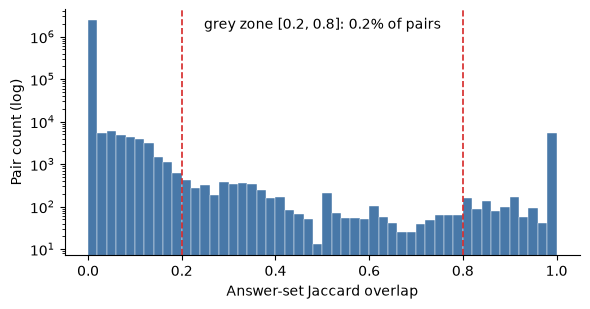

saved: /workspace/SPARQL-Embeddings/results/threshold_sensitivity/jaccard_histogram_wikidata.pdf


In [4]:
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(pair_j, bins=50, color="#4878a8", edgecolor="white", linewidth=0.3)
ax.set_yscale("log")
for x in [0.2, 0.8]:
    ax.axvline(x, color="#d62728", linestyle="--", linewidth=1.2)
ax.text(0.5, 0.92, f"grey zone [0.2, 0.8]: {grey:.1%} of pairs",
        transform=ax.transAxes, ha="center", fontsize=10)
ax.set_xlabel("Answer-set Jaccard overlap")
ax.set_ylabel("Pair count (log)")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

histogram_path = OUT_DIR / "jaccard_histogram_wikidata.pdf"
fig.savefig(histogram_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"saved: {histogram_path}")

### Experiment B — evaluation-side tau sweep (no retraining)

In [5]:
from evaluate_rq1 import load_triplets, build_global_corpus, build_eval_items

test_data = load_triplets(str(TESTSET_PATH))
global_corpus, seen_q = build_global_corpus(test_data)
raw_eval_items = build_eval_items(test_data, global_corpus, seen_q)

# Preserve original per-anchor candidate pools. We only:
#   1. drop anchors without oracle result sets,
#   2. remove exact self matches,
#   3. deduplicate candidates while preserving order.
# Candidates without oracle result sets remain in the ranking pool.
eval_records = []
for item in raw_eval_items:
    anchor, pool, original_positives = item[:3]
    if get_result_set(anchor) is None:
        continue
    seen_candidates, pool_dedup = set(), []
    for candidate in pool:
        if candidate == anchor or candidate in seen_candidates:
            continue
        seen_candidates.add(candidate)
        pool_dedup.append(candidate)
    if not pool_dedup:
        continue
    eval_records.append({"anchor": anchor, "pool": pool_dedup, "original_positives": original_positives})

anchors = [r["anchor"] for r in eval_records]
# Union of all candidates, preserving first-seen order.
candidate_corpus = list(dict.fromkeys(c for r in eval_records for c in r["pool"]))
candidate_index = {c: i for i, c in enumerate(candidate_corpus)}
pool_indices = [np.asarray([candidate_index[c] for c in r["pool"]], dtype=np.int32) for r in eval_records]

n_pool_candidates = sum(len(r["pool"]) for r in eval_records)
n_pool_candidates_with_oracle = sum(
    get_result_set(c) is not None for r in eval_records for c in r["pool"]
)

print(f"raw eval items: {len(raw_eval_items):,}")
print(f"usable anchors with oracle results: {len(eval_records):,}")
print(f"unique candidate corpus: {len(candidate_corpus):,}")
print(f"total anchor-pool candidate entries: {n_pool_candidates:,}")
print(f"pool candidate entries with oracle results: {n_pool_candidates_with_oracle:,} / "
      f"{n_pool_candidates:,} ({n_pool_candidates_with_oracle / n_pool_candidates:.2%})")

raw eval items: 186
usable anchors with oracle results: 186
unique candidate corpus: 2,229
total anchor-pool candidate entries: 414,408
pool candidate entries with oracle results: 414,408 / 414,408 (100.00%)


In [6]:
# J_pool[i][p] corresponds to eval_records[i]["pool"][p]; NaN means the
# candidate has no cached oracle result set.
J_pool = []
for record in tqdm(eval_records, desc="pool relevance Jaccard"):
    Ra = get_result_set(record["anchor"])
    values = np.full(len(record["pool"]), np.nan, dtype=np.float32)
    for p, candidate in enumerate(record["pool"]):
        Rc = get_result_set(candidate)
        if Rc is not None:
            values[p] = jaccard(Ra, Rc)
    J_pool.append(values)

# Coverage diagnostic: how many anchors have >=1 relevant candidate at each tau?
coverage_rows = []
for tau in TAUS:
    n_with_relevant = sum(bool(np.any(np.isfinite(v) & (v >= tau))) for v in J_pool)
    coverage_rows.append({"tau": tau, "anchors_total": len(eval_records),
                           "anchors_with_at_least_one_relevant_candidate": n_with_relevant,
                           "coverage": n_with_relevant / len(eval_records)})
coverage = pd.DataFrame(coverage_rows)
display(coverage)
coverage.to_csv(OUT_DIR / "tau_anchor_coverage_wikidata.csv", index=False)

# Fixed evaluation population: use the same anchors for every tau. Retain
# anchors with >=1 relevant candidate at the strictest threshold, max(TAUS) --
# so every retained anchor also has one at every lower threshold.
max_tau = max(TAUS)
fixed_eval_indices = np.asarray(
    [i for i, v in enumerate(J_pool) if np.any(np.isfinite(v) & (v >= max_tau))], dtype=np.int32,
)
if len(fixed_eval_indices) == 0:
    raise RuntimeError(f"No anchors have a relevant candidate at tau={max_tau}. "
                        f"Inspect tau_anchor_coverage_wikidata.csv.")
print(f"fixed evaluation population: {len(fixed_eval_indices):,} anchors (eligible at tau={max_tau})")

pool relevance Jaccard: 100%|██████████| 186/186 [00:00<00:00, 307.32it/s]


,tau,anchors_total,anchors_with_at_least_one_relevant_candidate,coverage
0,0.6,186,176,0.946237
1,0.7,186,175,0.940860
2,0.8,186,175,0.940860
3,0.9,186,175,0.940860


fixed evaluation population: 175 anchors (eligible at tau=0.9)


In [7]:
from sentence_transformers import SentenceTransformer
from sparqlce.embedder import SPARQLEmbedder


def as_numpy_2d(x):
    """Convert model output to a 2D float32 NumPy array."""
    if torch.is_tensor(x):
        x = x.detach().cpu().numpy()
    x = np.asarray(x, dtype=np.float32)
    if x.ndim == 1:
        x = x[None, :]
    if x.ndim != 2:
        raise ValueError(f"expected 2D embeddings, got shape {x.shape}")
    return x


def l2_normalize(x):
    x = np.asarray(x, dtype=np.float32)
    norms = np.clip(np.linalg.norm(x, axis=1, keepdims=True), 1e-12, None)
    return x / norms


def embed_sparqlce(model, texts, batch_size=32):
    batches = []
    for start in tqdm(range(0, len(texts), batch_size), desc="SparqlCE embedding", leave=False):
        batch_embeddings = model.encode(texts[start:start + batch_size])
        batches.append(as_numpy_2d(batch_embeddings))
    return l2_normalize(np.vstack(batches))


model_sims = {}

# ---- SparqlCE ----
print("\nLoading SparqlCE...")
sparqlce = SPARQLEmbedder(str(SPARQLCE_CKPT))
print("Embedding anchors with SparqlCE...")
A = embed_sparqlce(sparqlce, anchors, batch_size=32)
print("Embedding candidate corpus with SparqlCE...")
C = embed_sparqlce(sparqlce, candidate_corpus, batch_size=32)
model_sims["SparqlCE"] = (A @ C.T).astype(np.float32, copy=False)
del sparqlce, A, C
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# ---- Baselines ----
for config in BASELINES:
    name, model_id = config["name"], config["model_id"]
    prefix, batch_size = config.get("prefix", ""), config.get("batch_size", 32)
    print(f"\nEmbedding with {name} ({model_id})")
    model = SentenceTransformer(model_id, device=DEVICE)
    anchor_inputs = [prefix + q for q in anchors]
    candidate_inputs = [prefix + q for q in candidate_corpus]
    A = model.encode(anchor_inputs, convert_to_numpy=True, normalize_embeddings=True,
                      show_progress_bar=True, batch_size=batch_size).astype(np.float32, copy=False)
    C = model.encode(candidate_inputs, convert_to_numpy=True, normalize_embeddings=True,
                      show_progress_bar=True, batch_size=batch_size).astype(np.float32, copy=False)
    model_sims[name] = (A @ C.T).astype(np.float32, copy=False)
    del model, A, C, anchor_inputs, candidate_inputs
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nsimilarity matrix shapes:")
for name, sims in model_sims.items():
    print(f"  {name}: {sims.shape}")

expected_shape = (len(anchors), len(candidate_corpus))
for name, sims in model_sims.items():
    if sims.shape != expected_shape:
        raise RuntimeError(f"{name} similarity matrix has shape {sims.shape}; expected {expected_shape}")


Loading SparqlCE...
Loading model from /workspace/SPARQL-Embeddings/sparqlce/models/wikidata_model_mrr_0.3238.pt...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 38810.87it/s]


Embedding anchors with SparqlCE...


Embedding candidate corpus with SparqlCE...



Embedding with E5-base-v2 (intfloat/e5-base-v2)


Batches: 100%|██████████| 70/70 [00:05<00:00, 13.66it/s]



Embedding with Qwen3-Embedding (Qwen/Qwen3-Embedding-0.6B)


Batches: 100%|██████████| 279/279 [00:10<00:00, 25.45it/s]



similarity matrix shapes:
  SparqlCE: (186, 2229)
  E5-base-v2: (186, 2229)
  Qwen3-Embedding: (186, 2229)


In [8]:
def rank_pools_once(sims, pool_indices):
    """One local ranking per anchor: local positions into that anchor's own
    candidate pool, sorted highest to lowest similarity."""
    rankings = []
    for i, indices in enumerate(pool_indices):
        pool_scores = sims[i, indices]
        rankings.append(np.argsort(-pool_scores, kind="stable"))  # stable sort => deterministic ties
    return rankings


model_rankings = {name: rank_pools_once(sims, pool_indices) for name, sims in model_sims.items()}
print("rankings precomputed for:", list(model_rankings))

rankings precomputed for: ['SparqlCE', 'E5-base-v2', 'Qwen3-Embedding']


In [9]:
def mrr_hits_at_k_from_rankings(rankings, jaccard_by_pool, tau, k, eval_indices):
    """Evaluate a fixed set of anchors. Relevance: candidate is relevant iff
    answer-set Jaccard >= tau. eval_indices is the same at every tau, so the
    denominator does not change."""
    reciprocal_ranks, hits = [], []
    for i in eval_indices:
        relevant = np.isfinite(jaccard_by_pool[i]) & (jaccard_by_pool[i] >= tau)
        if not relevant.any():
            raise RuntimeError(f"anchor index {i} has no relevant candidate at tau={tau}; "
                                f"the fixed evaluation population is inconsistent")
        relevant_in_topk = relevant[rankings[i][:k]]
        hit_positions = np.flatnonzero(relevant_in_topk)
        if len(hit_positions):
            reciprocal_ranks.append(1.0 / (int(hit_positions[0]) + 1))
            hits.append(1.0)
        else:
            reciprocal_ranks.append(0.0)
            hits.append(0.0)
    return float(np.mean(reciprocal_ranks)), float(np.mean(hits)), len(reciprocal_ranks)


# ---- Run the tau sweep ----
rows = []
for tau in TAUS:
    for model_name, rankings in model_rankings.items():
        mrr, hits, n = mrr_hits_at_k_from_rankings(
            rankings=rankings, jaccard_by_pool=J_pool, tau=tau, k=TOPK, eval_indices=fixed_eval_indices,
        )
        rows.append({"tau": tau, "model": model_name, f"MRR@{TOPK}": mrr, f"Hits@{TOPK}": hits,
                     "n_anchors": n, "population_rule": f"fixed intersection: relevant candidate exists at tau={max_tau}"})

mini_long = pd.DataFrame(rows)
metric_col = f"MRR@{TOPK}"
full_mrr_pivot = mini_long.pivot(index="tau", columns="model", values=metric_col)

baseline_names = [name for name in model_rankings if name != "SparqlCE"]
if not baseline_names:
    raise RuntimeError("At least one baseline is required for the mini-table.")

best_baseline_mrr = full_mrr_pivot[baseline_names].max(axis=1)
best_baseline_name = full_mrr_pivot[baseline_names].idxmax(axis=1)

paper_table = pd.DataFrame({
    "SparqlCE": full_mrr_pivot["SparqlCE"],
    "best baseline": best_baseline_mrr,
    "best baseline model": best_baseline_name,
})
paper_table["gap (x)"] = paper_table["SparqlCE"] / paper_table["best baseline"]
paper_table["n_anchors"] = len(fixed_eval_indices)

print("\nFull MRR pivot:")
display(full_mrr_pivot.round(4))
print("\nPaper mini-table:")
display(paper_table.round(4))

# ---- Save outputs ----
mini_long.to_json(OUT_DIR / "tau_sweep_wikidata.json", orient="records", indent=2)
mini_long.to_csv(OUT_DIR / "tau_sweep_wikidata.csv", index=False)
paper_table.to_csv(OUT_DIR / "tau_sensitivity_mini_table_wikidata.csv")

# ---- LaTeX rows ----
print("\nLaTeX rows:")
for tau, row in paper_table.iterrows():
    marker = r"\;(paper)" if np.isclose(tau, 0.8) else ""
    print(f"$\\tau={tau:.1f}${marker} & {row['SparqlCE']:.4f} & "
          f"{row['best baseline']:.4f} & {row['gap (x)']:.2f}$\\times$ \\\\")


Full MRR pivot:


model,E5-base-v2,Qwen3-Embedding,SparqlCE
tau,,,
0.6,0.562,0.561,0.6394
0.7,0.562,0.561,0.6394
0.8,0.562,0.561,0.6394
0.9,0.562,0.561,0.6394



Paper mini-table:


,SparqlCE,best baseline,best baseline model,gap (x),n_anchors
tau,,,,,
0.6,0.6394,0.562,E5-base-v2,1.1378,175
0.7,0.6394,0.562,E5-base-v2,1.1378,175
0.8,0.6394,0.562,E5-base-v2,1.1378,175
0.9,0.6394,0.562,E5-base-v2,1.1378,175



LaTeX rows:
$\tau=0.6$ & 0.6394 & 0.5620 & 1.14$\times$ \\
$\tau=0.7$ & 0.6394 & 0.5620 & 1.14$\times$ \\
$\tau=0.8$\;(paper) & 0.6394 & 0.5620 & 1.14$\times$ \\
$\tau=0.9$ & 0.6394 & 0.5620 & 1.14$\times$ \\


### Summary

In [10]:
print("Experiment A")
print("------------")
print(f"grey-zone fraction [0.2, 0.8]: {grey:.4%}")
print(f"histogram: {OUT_DIR / 'jaccard_histogram_wikidata.pdf'}")
print(f"nearby-threshold counts: {OUT_DIR / 'jaccard_nearby_threshold_counts_wikidata.csv'}")

print("\nExperiment B")
print("------------")
print(f"fixed evaluation anchors: {len(fixed_eval_indices):,} (eligible at tau={max_tau})")
print(f"mini-table: {OUT_DIR / 'tau_sensitivity_mini_table_wikidata.csv'}")
print(f"coverage table: {OUT_DIR / 'tau_anchor_coverage_wikidata.csv'}")
print("\nMini-table:")
display(paper_table.round(4))

Experiment A
------------
grey-zone fraction [0.2, 0.8]: 0.1778%
histogram: /workspace/SPARQL-Embeddings/results/threshold_sensitivity/jaccard_histogram_wikidata.pdf
nearby-threshold counts: /workspace/SPARQL-Embeddings/results/threshold_sensitivity/jaccard_nearby_threshold_counts_wikidata.csv

Experiment B
------------
fixed evaluation anchors: 175 (eligible at tau=0.9)
mini-table: /workspace/SPARQL-Embeddings/results/threshold_sensitivity/tau_sensitivity_mini_table_wikidata.csv
coverage table: /workspace/SPARQL-Embeddings/results/threshold_sensitivity/tau_anchor_coverage_wikidata.csv

Mini-table:


,SparqlCE,best baseline,best baseline model,gap (x),n_anchors
tau,,,,,
0.6,0.6394,0.562,E5-base-v2,1.1378,175
0.7,0.6394,0.562,E5-base-v2,1.1378,175
0.8,0.6394,0.562,E5-base-v2,1.1378,175
0.9,0.6394,0.562,E5-base-v2,1.1378,175


**Used in the paper** ([Sections/experiments-v2.tex](../../../sparql-embeddings-latex/Sections/experiments-v2.tex),
`\paragraph{Threshold sensitivity.}`, and
[tables/tab-threshold-sensitivity.tex](../../../sparql-embeddings-latex/tables/tab-threshold-sensitivity.tex)):
the 0.1778%% grey-zone figure and the four-row tau-sweep mini-table above.